# Prédire les annulations de réservations hôtelières
Auteur : Zohair / Brice / Mouna

**Question métier** : avec les informations connues au moment de la réservation, peut-on anticiper son annulation, et comment en faire une décision pour la direction ?

**Données** : hotel_bookings.csv (Kaggle, Hotel Booking Demand). Une ligne = une réservation. Variable à prédire : is_canceled.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", None)
df_raw = pd.read_csv("../data/hotel_bookings.csv")
print(df_raw.shape)
df_raw.head()

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Le fichier contient 119 390 lignes et 32 colonnes, comme annoncé dans le brief. Chaque ligne est une réservation : on y trouve l'hôtel (ici « Resort Hotel » pour les premières lignes), la cible is_canceled, le délai de réservation (lead_time) et la date d'arrivée découpée en plusieurs colonnes (année, mois, semaine, jour).

## 1. Structure du jeu 

In [2]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [3]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


- is_canceled a une moyenne de 0,370416 : environ 37 % des réservations du fichier sont annulées. Les deux classes sont donc déséquilibrées sans l'être fortement.
- lead_time : médiane 69 jours, moyenne 104, maximum 737. Quelques réservations faites très longtemps à l'avance tirent la moyenne vers le haut.
- adr (prix moyen par nuit) : minimum -6,38 et maximum 5 400, alors que la médiane est à 94,575. Un prix négatif est impossible et 5 400 est très loin du 3e quartile (126) : deux valeurs à examiner.
- adults va de 0 à 55 : une réservation sans adulte ou avec 55 adultes est à vérifier. children et babies montent jusqu'à 10.
- stays_in_weekend_nights monte à 19 et stays_in_week_nights à 50 : séjours très longs, peut-être réels.
- Plusieurs colonnes sont presque toujours à 0 (médiane 0) avec quelques grosses valeurs : previous_cancellations (max 26), booking_changes (max 21), days_in_waiting_list (max 391), required_car_parking_spaces (max 8).
- agent et company sont des identifiants : leur moyenne n'a pas de sens.

## 3. Valeurs manquantes

In [4]:
manquants = df_raw.isna().sum()
print(manquants[manquants > 0])
print((manquants[manquants > 0] / len(df_raw) * 100).round(2))

children         4
country        488
agent        16340
company     112593
dtype: int64
children     0.00
country      0.41
agent       13.69
company     94.31
dtype: float64


4 colonnes ont des valeurs manquantes :
- children : 4 lignes (0,00 %). Négligeable, non bloquant.
- country : 488 lignes (0,41 %). Faible, non bloquant.
- agent : 16 340 lignes (13,69 %). Un vide signifie probablement « réservation sans agence » plutôt qu'une erreur (à garder en tête, pas vérifiable directement).
- company : 112 593 lignes (94,31 %). Presque toujours vide, donc probablement « réservation sans entreprise ». Trop peu remplie pour être utile telle quelle.

## 4. Doublons

In [5]:
print(df_raw.duplicated().sum())

31994


In [6]:
doublon = df_raw.duplicated()
print(round(doublon.mean() * 100, 2))
print(df_raw.groupby(doublon)["is_canceled"].mean())
print(df_raw[doublon]["hotel"].value_counts())
print(df_raw[doublon]["market_segment"].value_counts())

26.8
False    0.274898
True     0.631337
Name: is_canceled, dtype: float64
hotel
City Hotel      25902
Resort Hotel     6092
Name: count, dtype: int64
market_segment
Groups           14869
Offline TA/TO    10330
Online TA         4859
Corporate         1083
Direct             802
Complementary       41
Aviation            10
Name: count, dtype: int64


Le fichier contient 31 994 lignes strictement identiques à une autre, soit 26,8 % des lignes.

- Elles sont surtout au City Hotel (25 902, contre 6 092 au Resort Hotel).
- Leur segment est surtout Groups (14 869) et Offline TA/TO (10 330), c'est-à-dire des groupes et des agences hors ligne.
- Leur taux d'annulation est de 0,631337, contre 0,274898 pour les autres lignes.

Le fichier n'a pas de numéro de réservation : une partie de ces lignes peut correspondre à de vraies réservations multiples (un groupe qui réserve plusieurs chambres identiques), ce que le poids de Groups rend crédible. Mais rien ne permet de distinguer une vraie réservation d'une copie.

### Décision : suppression des doublons

In [7]:
df = df_raw.drop_duplicates()
print(len(df_raw), len(df), len(df_raw) - len(df))
print(round(df_raw["is_canceled"].mean() * 100, 2), round(df["is_canceled"].mean() * 100, 2))

119390 87396 31994
37.04 27.49


On supprime les 31 994 doublons exacts : il reste 87 396 réservations. df_raw reste intact, la suite du travail se fait sur df.

Pourquoi :
- Le fichier n'a pas de numéro de réservation, on ne peut donc pas prouver que deux lignes identiques sont deux réservations différentes.
- Pour le modèle, une même ligne pourrait se retrouver à la fois dans l'entraînement et dans le test, ce qui donnerait des scores trop optimistes.

Effet : le taux d'annulation passe de 37,04 % à 27,49 %, car les doublons étaient beaucoup plus souvent annulés. C'est une limite à garder en tête : si une partie de ces lignes étaient de vraies réservations de groupe, on sous-estime un peu les annulations des groupes.

In [8]:
personnes = df["adults"] + df["children"] + df["babies"]
nuits = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
print((personnes == 0).sum())
print((nuits == 0).sum())
print((df["adr"] < 0).sum())
print((df["adr"] == 0).sum())

166
651
1
1778


Sur les 87 396 réservations restantes :
- 166 n'ont aucune personne (0 adulte, 0 enfant, 0 bébé) ;
- 651 ont 0 nuit ;
- 1 a un prix par nuit négatif ;
- 1 778 ont un prix par nuit à 0.

In [9]:
print(df[df["adr"] == 0]["market_segment"].value_counts())
print(df[nuits == 0]["is_canceled"].mean())
print(df[personnes == 0]["is_canceled"].mean())
print(df[df["adr"] < 0][["hotel", "market_segment", "adr", "is_canceled"]])

market_segment
Complementary    640
Online TA        352
Offline TA/TO    260
Direct           227
Groups           220
Corporate         74
Aviation           5
Name: count, dtype: int64
0.0445468509984639
0.0963855421686747
              hotel market_segment   adr  is_canceled
14969  Resort Hotel         Groups -6.38            0


- Prix à 0 (1 778) : le premier segment est Complementary (640), c'est-à-dire des séjours offerts, donc un 0 normal. Les autres viennent de tous les segments (Online TA 352, Offline TA/TO 260, Direct 227, Groups 220...) : ce sont peut-être des promotions ou des séjours inclus dans un forfait, on ne peut pas le vérifier.
- 0 nuit (651) : seulement 4,45 % sont annulées (0,0445), bien moins que la moyenne de 27,49 %. Ce sont probablement des réservations à la journée réellement honorées, plutôt que des erreurs.
- Aucune personne (166) : 9,64 % sont annulées (0,0964). Une réservation sans aucun client n'a pas de sens, c'est une erreur de saisie.
- Prix négatif (1 ligne) : Resort Hotel, segment Groups, -6,38, non annulée. Probablement une correction comptable, impossible comme prix.

Décisions pour le nettoyage :
- supprimer les 166 réservations sans personne et la ligne au prix négatif ;
- garder les prix à 0 et les réservations à 0 nuit, qui semblent réels, en le signalant.

## 6. Catégories particulières

In [10]:
for col in ["meal", "market_segment", "distribution_channel", "deposit_type", "customer_type"]:
    print(df[col].value_counts(), "\n")

meal
BB           67978
SC            9481
HB            9085
Undefined      492
FB             360
Name: count, dtype: int64 

market_segment
Online TA        51618
Offline TA/TO    13889
Direct           11804
Groups            4942
Corporate         4212
Complementary      702
Aviation           227
Undefined            2
Name: count, dtype: int64 

distribution_channel
TA/TO        69141
Direct       12988
Corporate     5081
GDS            181
Undefined        5
Name: count, dtype: int64 

deposit_type
No Deposit    86251
Non Refund     1038
Refundable      107
Name: count, dtype: int64 

customer_type
Transient          71986
Transient-Party    11727
Contract            3139
Group                544
Name: count, dtype: int64 



- meal (formule repas) : BB 67 978, SC 9 481, HB 9 085, Undefined 492, FB 360. D'après la description du jeu de données, BB = petit-déjeuner, HB = demi-pension, FB = pension complète, et SC comme Undefined veulent dire « sans formule repas ». Undefined n'est donc pas une erreur, c'est un deuxième nom pour SC.
- market_segment : 8 valeurs, dont Undefined pour 2 réservations seulement. Online TA domine (51 618).
- distribution_channel : Undefined pour 5 réservations. TA/TO domine (69 141).
- deposit_type : No Deposit 86 251, Non Refund 1 038, Refundable 107. Presque toutes les réservations sont sans acompte.
- customer_type : 4 valeurs, rien d'anormal.

Décisions pour le nettoyage :
- dans meal, regrouper Undefined avec SC ;
- supprimer les réservations où market_segment ou distribution_channel vaut Undefined (très peu de lignes, catégorie inconnue).

## 7. Valeurs extrêmes

In [11]:
cols = ["hotel", "market_segment", "adults", "children", "babies", "stays_in_week_nights", "lead_time", "adr", "is_canceled"]
print(df.nlargest(3, "adr")[cols])
print(df.nlargest(3, "adults")[cols])
print(df.nlargest(3, "babies")[cols])
print(df.nlargest(3, "lead_time")[cols])

               hotel market_segment  adults  children  babies  \
48515     City Hotel  Offline TA/TO       2       0.0       0   
111403    City Hotel  Offline TA/TO       1       0.0       0   
15083   Resort Hotel      Corporate       2       0.0       0   

        stays_in_week_nights  lead_time     adr  is_canceled  
48515                      1         35  5400.0            1  
111403                     1          0   510.0            0  
15083                      1          1   508.0            0  
             hotel market_segment  adults  children  babies  \
2173  Resort Hotel         Direct      55       0.0       0   
1643  Resort Hotel         Direct      50       0.0       0   
1539  Resort Hotel         Direct      40       0.0       0   

      stays_in_week_nights  lead_time  adr  is_canceled  
2173                     0        338  0.0            1  
1643                     2        336  0.0            1  
1539                     3        304  0.0            1  
  

- Prix par nuit : la plus haute valeur est 5 400 (City Hotel, Offline TA/TO, 2 adultes, 1 nuit, annulée). Les deux suivantes sont à 510 et 508 : 5 400 est isolé, c'est très probablement une erreur de saisie.
- Adultes : les 3 plus grandes valeurs (55, 50 et 40 adultes) sont toutes au Resort Hotel, en Direct, avec un prix à 0, un délai de plus de 300 jours, et toutes annulées. Ressemble à des blocs de chambres posés puis annulés plutôt qu'à de vraies réservations.
- Bébés : 10 bébés pour 2 adultes (City Hotel, 84,45 par nuit) et 9 bébés pour 1 adulte (95 par nuit), non annulées. Le prix est normal pour une chambre classique : probablement une erreur de saisie. La 3e (2 bébés) est plausible.
- Délai : 737, 709 et 629 jours. C'est long mais possible (réservation 2 ans à l'avance), aucune autre valeur n'est anormale sur ces lignes. On les garde.

In [12]:
print(df[df["adults"] > 10][cols])
print(df.nlargest(3, "children")[cols])

             hotel market_segment  adults  children  babies  \
1539  Resort Hotel         Direct      40       0.0       0   
1587  Resort Hotel  Offline TA/TO      26       0.0       0   
1643  Resort Hotel         Direct      50       0.0       0   
1752  Resort Hotel  Offline TA/TO      26       0.0       0   
1884  Resort Hotel  Offline TA/TO      26       0.0       0   
1917  Resort Hotel         Direct      27       0.0       0   
1962  Resort Hotel         Direct      27       0.0       0   
2003  Resort Hotel  Offline TA/TO      26       0.0       0   
2164  Resort Hotel  Offline TA/TO      26       0.0       0   
2173  Resort Hotel         Direct      55       0.0       0   
2228  Resort Hotel         Direct      20       0.0       0   
2418  Resort Hotel         Direct      20       0.0       0   

      stays_in_week_nights  lead_time  adr  is_canceled  
1539                     3        304  0.0            1  
1587                     5        333  0.0            1  
1643  

- Plus de 10 adultes : 12 réservations, de 20 à 55 adultes. Toutes au Resort Hotel, en Direct ou Offline TA/TO, avec un prix à 0, un délai de 304 à 361 jours, et toutes annulées. Ce sont probablement des blocs de chambres posés à l'avance puis libérés, pas des réservations de clients. Les garder apprendrait au modèle une règle artificielle (« beaucoup d'adultes + prix 0 = annulation »).
- Enfants : une réservation a 10 enfants pour 2 adultes à 133,16 par nuit, un prix de chambre normal : probablement une erreur de saisie. Les suivantes (3 enfants) sont plausibles.

Décisions pour le nettoyage :
- supprimer la réservation à 5 400 par nuit ;
- supprimer les 12 réservations de plus de 10 adultes ;
- supprimer la réservation à 10 enfants et les 2 réservations à 9 et 10 bébés ;
- garder les délais très longs.

| Problème | Ce qu'on a vu | Décision |
|---|---|---|
| Doublons exacts | 31 994 lignes (26,8 %), annulées à 63 % contre 27 % | Supprimés (déjà fait), reste 87 396 lignes |
| children vide | 4 lignes dans le fichier brut | Remplacer par 0 |
| country vide | 488 lignes dans le fichier brut | Remplacer par "Unknown" |
| agent vide | 16 340 lignes dans le fichier brut | Remplacer par 0 (sans agence) |
| company vide | 112 593 lignes (94,31 %) dans le fichier brut | Supprimer la colonne |
| Aucune personne | 166 réservations | Supprimer |
| Prix négatif | 1 réservation (-6,38) | Supprimer |
| Prix à 5 400 | 1 réservation, la suivante est à 510 | Supprimer |
| Plus de 10 adultes | 12 réservations, prix 0, toutes annulées | Supprimer |
| 10 enfants, 9 et 10 bébés | 3 réservations au prix d'une chambre normale | Supprimer |
| Undefined dans meal | 492 réservations, même sens que SC | Regrouper avec SC |
| Undefined dans market_segment / distribution_channel | 2 et 5 réservations | Supprimer |
| Prix à 0 | 1 778 réservations, dont 640 offertes | Garder |
| 0 nuit | 651 réservations, 4,45 % annulées | Garder |
| Délais très longs | jusqu'à 737 jours | Garder |
| reservation_status et sa date | contiennent l'issue de la réservation | Garder dans le CSV, exclure du modèle (fuite) |

## 9. Nettoyage

### 9.1 Valeurs manquantes

In [13]:
df = df.copy()
print(df[["children", "country", "agent", "company"]].isna().sum())
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")
df["agent"] = df["agent"].fillna(0)
df = df.drop(columns="company")
print(df.isna().sum().sum(), df.shape)

children        4
country       452
agent       12193
company     82137
dtype: int64
0 (87396, 31)


Après suppression des doublons, les vides sont moins nombreux que dans le fichier brut : children 4, country 452, agent 12 193, company 82 137 (contre 488, 16 340 et 112 593 avant). C'est logique, une partie des vides était dans les lignes en double.

children est remplacé par 0, country par "Unknown", agent par 0 (sans agence), et la colonne company est supprimée. Il ne reste aucune valeur manquante : 87 396 lignes, 31 colonnes.

### 9.2 Réservations sans personne

In [14]:
avant = len(df)
df = df[df["adults"] + df["children"] + df["babies"] > 0]
print(avant - len(df), len(df))

166 87230


166 réservations sans aucune personne sont supprimées, comme prévu à l'exploration. Il reste 87 230 réservations.

### 9.3 Prix aberrants (négatif et 5 400)

In [15]:
avant = len(df)
df = df[(df["adr"] >= 0) & (df["adr"] < 5400)]
print(avant - len(df), len(df))

2 87228


Les 2 prix aberrants repérés à l'exploration sont supprimés : le prix négatif (-6,38) et le prix à 5 400. Il reste 87 228 réservations.

### 9.4 Plus de 10 adultes

In [16]:
avant = len(df)
df = df[df["adults"] <= 10]
print(avant - len(df), len(df))

12 87216


Les 12 réservations de plus de 10 adultes (blocs de chambres au prix de 0, toutes annulées) sont supprimées. Il reste 87 216 réservations.

### 9.5 Enfants et bébés aberrants

In [17]:
avant = len(df)
df = df[(df["children"] < 10) & (df["babies"] < 9)]
print(avant - len(df), len(df))

3 87213


Les 3 réservations aberrantes sont supprimées : 10 enfants pour 2 adultes, 9 bébés et 10 bébés, toutes au prix d'une chambre normale. Il reste 87 213 réservations.

### 9.6 Catégories Undefined

In [18]:
avant = len(df)
df = df[(df["market_segment"] != "Undefined") & (df["distribution_channel"] != "Undefined")]
df["meal"] = df["meal"].replace("Undefined", "SC")
print(avant - len(df), len(df))
print(df["meal"].value_counts())

5 87208
meal
BB    67889
SC     9883
HB     9076
FB      360
Name: count, dtype: int64


5 réservations avec une catégorie Undefined sont supprimées. À l'exploration, on avait vu 2 Undefined dans market_segment et 5 dans distribution_channel : l'écart vient probablement de lignes qui avaient Undefined dans les deux colonnes à la fois. Dans meal, Undefined est remplacé par SC : il reste 4 formules (BB 67 889, SC 9 883, HB 9 076, FB 360). Il reste 87 208 réservations.

### 9.7 Bilan du nettoyage

In [19]:
print(len(df_raw), len(df), len(df_raw) - len(df), round((len(df_raw) - len(df)) / len(df_raw) * 100, 2))
print(round(df_raw["is_canceled"].mean() * 100, 2), round(df["is_canceled"].mean() * 100, 2))
print(df["hotel"].value_counts())
print(df[["adults", "children", "babies", "adr"]].agg(["min", "max"]))

119390 87208 32182 26.96
37.04 27.51
hotel
City Hotel      53267
Resort Hotel    33941
Name: count, dtype: int64
     adults  children  babies    adr
min       0       0.0       0    0.0
max      10       3.0       2  510.0


| | Avant | Après |
|---|---|---|
| Réservations | 119 390 | 87 208 |
| Supprimées | | 32 182 (26,96 %) |
| Taux d'annulation | 37,04 % | 27,51 % |

Après nettoyage, il reste 53 267 réservations au City Hotel et 33 941 au Resort Hotel.

Presque toutes les suppressions viennent des doublons (31 994). Les autres corrections (personnes, prix, catégories) ne concernent que quelques dizaines de lignes.

Vérification des cas pièges : adults va maintenant de 0 à 10, children de 0 à 3, babies de 0 à 2, et adr de 0 à 510. Il n'y a plus de prix négatif ni de valeur à 5 400.

### 9.8 Export du fichier propre

In [20]:
df.to_csv("../data/hotel_bookings_clean.csv", index=False)

## 10. Analyses descriptives des annulations

hotel
City Hotel      30.09
Resort Hotel    23.46
Name: is_canceled, dtype: float64


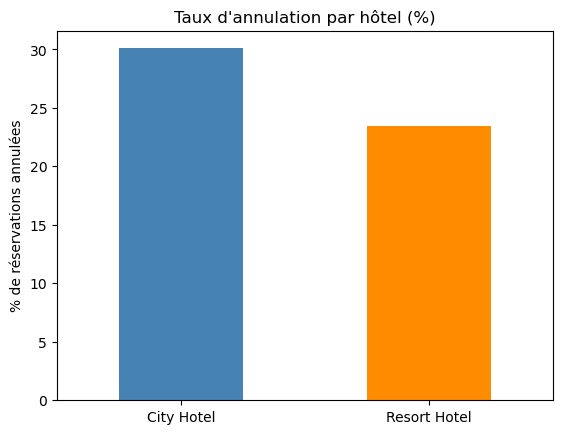

In [21]:
PALETTE = ["steelblue", "darkorange"]

taux_hotel = df.groupby("hotel")["is_canceled"].mean() * 100
print(taux_hotel.round(2))
taux_hotel.plot(kind="bar", color=PALETTE)
plt.title("Taux d'annulation par hôtel (%)")
plt.ylabel("% de réservations annulées")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

Après nettoyage, le City Hotel annule 30,09 % de ses réservations, contre 23,46 % pour le Resort Hotel. L'hôtel de ville est donc le plus exposé aux annulations.

## 11. le délai de réservation

hotel          City Hotel  Resort Hotel
lead_time                              
0-7 j               10.48          5.97
8-30 j              27.88         20.86
31-90 j             33.15         29.80
91-180 j            36.72         32.05
181-365 j           44.50         34.24
plus de 365 j       51.20         20.11
lead_time
0-7 j            18200
8-30 j           16324
31-90 j          22717
91-180 j         18223
181-365 j        11180
plus de 365 j      564
Name: count, dtype: int64


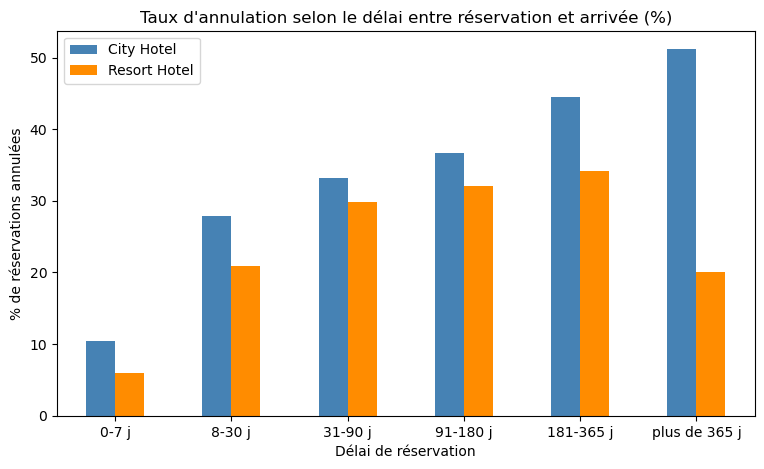

In [22]:
tranches = pd.cut(df["lead_time"], bins=[-1, 7, 30, 90, 180, 365, 800],
                  labels=["0-7 j", "8-30 j", "31-90 j", "91-180 j", "181-365 j", "plus de 365 j"])
taux_delai = df.groupby([tranches, "hotel"], observed=True)["is_canceled"].mean().unstack() * 100
print(taux_delai.round(2))
print(tranches.value_counts().sort_index())
taux_delai.plot(kind="bar", color=PALETTE, figsize=(9, 5))
plt.title("Taux d'annulation selon le délai entre réservation et arrivée (%)")
plt.ylabel("% de réservations annulées")
plt.xlabel("Délai de réservation")
plt.xticks(rotation=0)
plt.legend(title="")
plt.show()

Plus une réservation est faite tôt, plus elle risque d'être annulée.
- City Hotel : 10,48 % d'annulations pour les réservations faites 0 à 7 jours avant l'arrivée, puis 27,88 %, 33,15 %, 36,72 %, jusqu'à 44,50 % entre 181 et 365 jours.
- Resort Hotel : même tendance, de 5,97 % (0-7 jours) à 34,24 % (181-365 jours).
- Le saut le plus fort se fait dès qu'on dépasse 7 jours.
- La tranche « plus de 365 jours » ne compte que 564 réservations, contre 11 180 à 22 717 pour les autres tranches. Ses taux (51,20 % au City, 20,11 % au Resort) sont trop fragiles pour conclure.

Pour la direction : les réservations de dernière minute sont fiables, les réservations lointaines sont à surveiller.

## 12. le type d'acompte

              count  mean
deposit_type             
No Deposit    86064  26.7
Non Refund     1037  94.7
Refundable      107  24.3


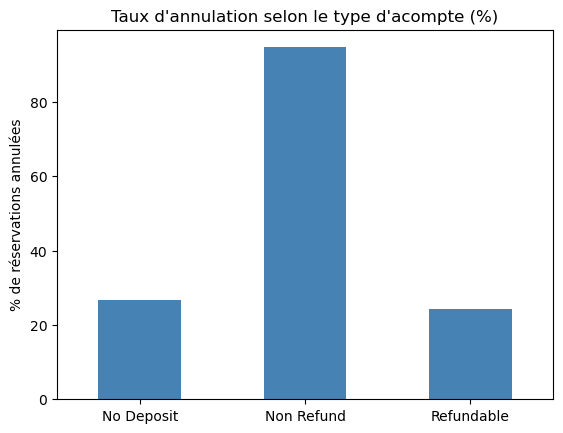

In [23]:
taux_depot = df.groupby("deposit_type")["is_canceled"].agg(["count", "mean"])
taux_depot["mean"] = (taux_depot["mean"] * 100).round(2)
print(taux_depot)
taux_depot["mean"].plot(kind="bar", color="steelblue")
plt.title("Taux d'annulation selon le type d'acompte (%)")
plt.ylabel("% de réservations annulées")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

In [24]:
nr = df[df["deposit_type"] == "Non Refund"]
print(nr["hotel"].value_counts())
print(nr["market_segment"].value_counts())
print(nr["country"].value_counts().head(5))
print(nr["lead_time"].median(), df["lead_time"].median())

hotel
City Hotel      844
Resort Hotel    193
Name: count, dtype: int64
market_segment
Groups           659
Offline TA/TO    286
Corporate         64
Online TA         18
Direct            10
Name: count, dtype: int64
country
PRT    982
GBR     14
DEU     13
ESP      9
FRA      4
Name: count, dtype: int64
189.0 49.0


Surprise : les réservations avec acompte non remboursable (Non Refund) sont annulées à 94,7 %, contre 26,7 % sans acompte et 24,3 % avec acompte remboursable.

Ces 1 037 réservations ont un profil très particulier :
- surtout au City Hotel (844, contre 193 au Resort) ;
- surtout des groupes (Groups 659) et des agences hors ligne (Offline TA/TO 286) ;
- presque toutes avec le Portugal comme pays (982), les autres pays n'en ont que 14 au plus ;
- réservées longtemps à l'avance : délai médian de 189 jours, contre 49 pour l'ensemble des réservations.

Ce sont donc probablement des blocs de chambres posés par des groupes ou des agences, puis libérés, plutôt que des clients individuels qui perdent leur argent. Les données ne permettent pas de le vérifier.

Pour la direction : ces annulations ne coûtent rien à l'hôtel, puisque l'acompte est conservé. Il n'est pas utile de les cibler en priorité.

## 13. Le segment de marché 

hotel           City Hotel  Resort Hotel
market_segment                          
Aviation             19.91           NaN
Complementary        10.74         16.40
Corporate            11.86         12.41
Direct               16.45         13.12
Groups               33.87         19.33
Offline TA/TO        17.35         12.01
Online TA            36.12         33.85
market_segment
Online TA        51551
Offline TA/TO    13848
Direct           11771
Groups            4921
Corporate         4199
Complementary      692
Aviation           226
Name: count, dtype: int64


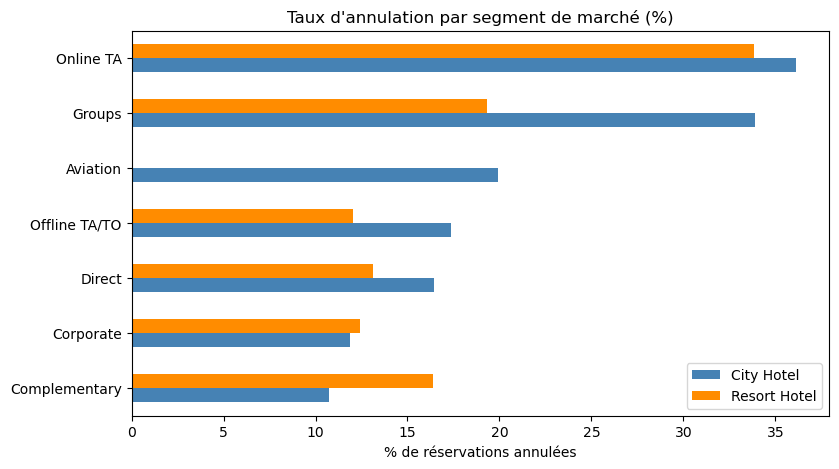

In [25]:
taux_segment = df.groupby(["market_segment", "hotel"])["is_canceled"].mean().unstack() * 100
print(taux_segment.round(2))
print(df["market_segment"].value_counts())
taux_segment.sort_values("City Hotel").plot(kind="barh", color=PALETTE, figsize=(9, 5))
plt.title("Taux d'annulation par segment de marché (%)")
plt.xlabel("% de réservations annulées")
plt.ylabel("")
plt.legend(title="")
plt.show()

- Les agences en ligne (Online TA) sont le segment le plus annulé dans les deux hôtels : 36,12 % au City Hotel et 33,85 % au Resort Hotel. C'est aussi de loin le plus gros segment (51 551 réservations).
- Les groupes (Groups) annulent beaucoup plus en ville (33,87 %) qu'au Resort (19,33 %).
- Les autres segments restent entre 10,74 % et 19,91 %. Les agences hors ligne (Offline TA/TO) annulent nettement moins que les agences en ligne : 17,35 % au City et 12,01 % au Resort.
- Aviation n'existe qu'au City Hotel et ne compte que 226 réservations : trop peu pour conclure.

Pour la direction : le canal en ligne est le premier levier, car il cumule le plus de réservations et le taux d'annulation le plus élevé.

## 14. La saisonalité

hotel               City Hotel  Resort Hotel
arrival_date_month                          
January                  28.02         13.97
February                 27.10         17.62
March                    28.21         17.51
April                    34.44         23.30
May                      32.32         23.66
June                     30.42         30.19
July                     33.09         30.13
August                   32.03         32.43
September                25.19         23.22
October                  26.86         18.79
November                 25.50         14.97
December                 32.66         18.83


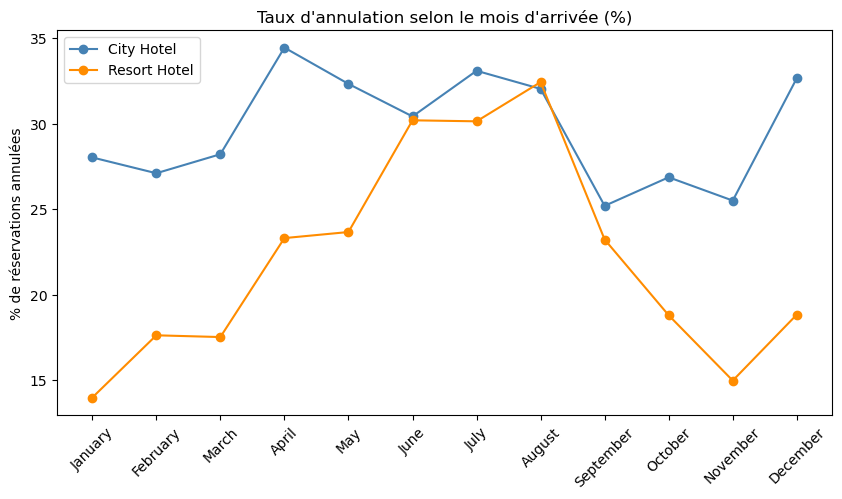

In [26]:
MOIS = ["January", "February", "March", "April", "May", "June",
        "July", "August", "September", "October", "November", "December"]
taux_mois = df.groupby(["arrival_date_month", "hotel"])["is_canceled"].mean().unstack() * 100
taux_mois = taux_mois.reindex(MOIS)
print(taux_mois.round(2))
taux_mois.plot(color=PALETTE, marker="o", figsize=(10, 5))
plt.title("Taux d'annulation selon le mois d'arrivée (%)")
plt.ylabel("% de réservations annulées")
plt.xlabel("")
plt.xticks(range(12), MOIS, rotation=45)
plt.legend(title="")
plt.show()

Les deux hôtels n'ont pas la même saisonnalité :
- Resort Hotel : très saisonnier. Le taux d'annulation est au plus bas en hiver (13,97 % en janvier, 14,97 % en novembre) et monte en été, jusqu'à 32,43 % en août. Les annulations frappent donc la haute saison, quand les chambres valent le plus.
- City Hotel : plus stable, entre 25,19 % (septembre) et 34,44 % (avril), avec un pic aussi en décembre (32,66 %).
- En août, les deux hôtels ont presque le même taux (32,03 % au City, 32,43 % au Resort).

Limite : les données vont de juillet 2015 à août 2017. Certains mois apparaissent sur 3 années, d'autres sur 2 seulement : les mois ne sont donc pas tous comparés sur la même période.

Pour la direction : au Resort, renforcer la prévention avant l'été ; au City, la vigilance doit rester constante toute l'année.

## 15. L'historique du client 

In [27]:
historique = df.groupby(["is_repeated_guest", "hotel"])["is_canceled"].mean().unstack() * 100
deja_annule = df.groupby([df["previous_cancellations"] > 0, "hotel"])["is_canceled"].mean().unstack() * 100
print(historique.round(2))
print(deja_annule.round(2))
print(df["is_repeated_guest"].value_counts())
print((df["previous_cancellations"] > 0).value_counts())

hotel              City Hotel  Resort Hotel
is_repeated_guest                          
0                       30.70         24.47
1                       11.35          4.22
hotel                   City Hotel  Resort Hotel
previous_cancellations                          
False                        29.22         22.81
True                         68.74         66.27
is_repeated_guest
0    83845
1     3363
Name: count, dtype: int64
previous_cancellations
False    85527
True      1681
Name: count, dtype: int64


**Observations : l'historique du client**

- Les clients fidèles annulent beaucoup moins : 11,35 % au City Hotel et 4,22 % au Resort Hotel, contre 30,70 % et 24,47 % pour les nouveaux clients.
- Les clients qui ont déjà annulé dans le passé annulent beaucoup plus : 68,74 % au City Hotel et 66,27 % au Resort Hotel, contre 29,22 % et 22,81 % pour les autres.
- Attention, ces deux groupes sont petits : 3 363 clients fidèles et 1 681 clients ayant déjà annulé, sur 87 208 réservations. La tendance est nette mais elle concerne peu de réservations.
- Même tendance que la requête R7 sur sql (les groupes ne sont pas découpés pareil, donc on compare la tendance, pas les chiffres exacts).

## 16. Comparaison des deux hôtels

In [28]:
comparaison = df.groupby("hotel").agg(
    reservations=("is_canceled", "count"),
    taux_annulation=("is_canceled", "mean"),
    prix_moyen=("adr", "mean"),
    delai_moyen=("lead_time", "mean"),
)
comparaison["taux_annulation"] = comparaison["taux_annulation"] * 100
comparaison.round(2)

,reservations,taux_annulation,prix_moyen,delai_moyen
hotel,,,,
City Hotel,53267,30.09,111.18,77.80
Resort Hotel,33941,23.46,99.10,83.29


**Observations : comparaison des deux hôtels**

- Le City Hotel a plus de réservations (53 267 contre 33 941) et annule plus (30,09 % contre 23,46 %).
- Le City Hotel est plus cher en moyenne : 111,18 contre 99,10 par nuit.
- Le Resort Hotel est réservé un peu plus tôt : 83,29 jours en moyenne avant l'arrivée, contre 77,80 pour le City Hotel.
- Le délai plus long au Resort ne donne donc pas plus d'annulations : le délai n'explique pas tout, le type d'hôtel compte aussi.

## Conclusion des analyses descriptives

1. **Le type d'hôtel** : le City Hotel annule plus que le Resort Hotel (30,09 % contre 23,46 %).
2. **Le délai de réservation** : plus on réserve tôt, plus on annule. Au City Hotel, on passe de 10,48 % (0-7 jours) à 51,20 % (plus de 365 jours).
3. **Le type d'acompte** : les réservations Non Refund annulent à 94,7 %, mais ce ne sont que 1 037 réservations. C'est un cas à part (probablement des blocs de groupes ou d'agences).
4. **Le segment de marché** : Online TA est le segment qui annule le plus dans les deux hôtels (36,12 % au City Hotel, 33,85 % au Resort Hotel).
5. **L'historique du client** : un client qui a déjà annulé annule beaucoup plus (68,74 % au City Hotel), un client fidèle beaucoup moins (11,35 %).

Ces variables (hôtel, délai, acompte, segment, historique) sont toutes connues au moment de la réservation : on peut les utiliser dans le modèle.